In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from features import load_application, add_bureau, add_prev, add_installments, make_xy

In [4]:
df = add_installments(add_prev(load_application()))
X, y = make_xy(df)
X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

/Users/daniil/projects/credit-scoring/features.py:20: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["DAYS_EMPLOYED_ANOM"] = (df["DAYS_EMPLOYED"] == 365243).astype(int)


In [5]:
model = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.05, verbose=-1, random_state=42)
model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], eval_metric="auc", callbacks=[lgb.early_stopping(100), lgb.log_evaluation(200)])

p_va = model.predict_proba(X_va)[:, 1]
auc = roc_auc_score(y_va, p_va)
print(f"AUC = {auc:.4f}, Gini = {2 * auc - 1:.4f}")

/Users/daniil/projects/credit-scoring/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
[200]	valid_0's auc: 0.769996	valid_0's binary_logloss: 0.242463
[400]	valid_0's auc: 0.770823	valid_0's binary_logloss: 0.242172
[600]	valid_0's auc: 0.771361	valid_0's binary_logloss: 0.242009
Early stopping, best iteration is:
[620]	valid_0's auc: 0.771549	valid_0's binary_logloss: 0.24194
AUC = 0.7715, Gini = 0.5431


In [6]:
contrib = model.predict(X_va, pred_contrib=True)
shap_df = pd.DataFrame(contrib[:, :-1], columns=X_va.columns, index=X_va.index)
base = contrib[0, -1]

raw = base + shap_df.sum(axis=1)
p_from_shap = 1 / (1 + np.exp(-raw))
print("вклады складываются в прогноз:", np.allclose(p_from_shap, p_va))
print("базовая вероятность:", round(1 / (1 + np.exp(-base)), 4))

вклады складываются в прогноз: True
базовая вероятность: 0.0524


In [8]:
shap_imp = shap_df.abs().mean().sort_values(ascending=False)
shap_imp.head(15)

EXT_SOURCE_3               0.338712
EXT_SOURCE_2               0.308142
EXT_SOURCE_1               0.156005
AMT_CREDIT                 0.149893
PREV_CREDIT_TO_APP_MEAN    0.133155
AMT_GOODS_PRICE            0.131715
CODE_GENDER                0.100673
DAYS_EMPLOYED              0.096778
ORGANIZATION_TYPE          0.095094
OWN_CAR_AGE                0.081997
INST_LATE_SHARE            0.079814
INST_PAYMENT_SUM           0.077630
NAME_EDUCATION_TYPE        0.069754
DAYS_BIRTH                 0.066358
PREV_REFUSED_SHARE         0.065172
dtype: float64

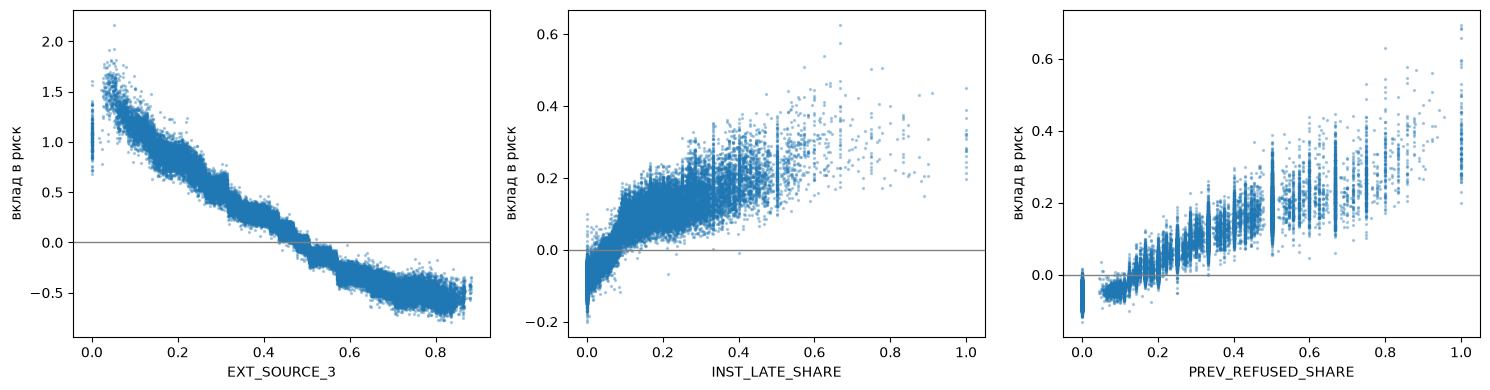

In [9]:
import matplotlib.pyplot as plt

features_to_plot = ["EXT_SOURCE_3", "INST_LATE_SHARE", "PREV_REFUSED_SHARE"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feat in zip(axes, features_to_plot):
    ax.scatter(X_va[feat], shap_df[feat], s=2, alpha=0.3)
    ax.axhline(0, color="grey", lw=1)
    ax.set_xlabel(feat)
    ax.set_ylabel("вклад в риск")
plt.tight_layout()

In [10]:
EXCLUDE = ["CODE_GENDER"]

REASONS = {
    "EXT_SOURCE_1": lambda v: f"внешний кредитный рейтинг №1: {v:.2f} из 1",
    "EXT_SOURCE_2": lambda v: f"внешний кредитный рейтинг №2: {v:.2f} из 1",
    "EXT_SOURCE_3": lambda v: f"внешний кредитный рейтинг №3: {v:.2f} из 1",
    "INST_LATE_SHARE": lambda v: f"{v:.0%} прошлых платежей внесены с опозданием",
    "INST_DPD_MAX": lambda v: f"максимальная просрочка платежа — {v:.0f} дн.",
    "INST_DPD_MEAN": lambda v: f"средняя просрочка платежа — {v:.1f} дн.",
    "INST_UNPAID_COUNT": lambda v: f"{v:.0f} платежей так и не поступили",
    "INST_PAID_RATIO": lambda v: f"по прошлым кредитам выплачено {v:.0%} от требуемого",
    "PREV_REFUSED_SHARE": lambda v: f"{v:.0%} прошлых заявок были отклонены",
    "PREV_REFUSED_COUNT": lambda v: f"{v:.0f} отказов по прошлым заявкам",
    "PREV_CREDIT_TO_APP_MEAN": lambda v: f"в прошлом выдавалось {v:.0%} от запрошенной суммы",
    "PREV_DAYS_DECISION_MAX": lambda v: f"предыдущая заявка была {-v:.0f} дн. назад",
    "BUREAU_DEBT_RATIO": lambda v: f"не погашено {v:.0%} суммы кредитов в других банках",
    "BUREAU_ACTIVE_COUNT": lambda v: f"{v:.0f} действующих кредитов в других банках",
    "BUREAU_DAYS_CREDIT_MAX": lambda v: f"новый кредит в другом банке {-v:.0f} дн. назад",
    "BUREAU_COUNT": lambda v: "нет кредитной истории в бюро" if v == 0 else f"{v:.0f} кредитов в бюро",
    "DAYS_EMPLOYED": lambda v: f"стаж на текущем месте: {-v / 365:.1f} г.",
    "DAYS_BIRTH": lambda v: f"возраст: {-v / 365:.0f}",
    "ORGANIZATION_TYPE": lambda v: f"сфера занятости: {v}",
    "OCCUPATION_TYPE": lambda v: f"профессия: {v}",
    "NAME_EDUCATION_TYPE": lambda v: f"образование: {v}",
}

def describe_feature(feature, value):
    if pd.isna(value):
        return f"нет данных: {feature}"
    if feature in REASONS:
        return REASONS[feature](value)
    if isinstance(value, (int, float, np.number)):
        value = f"{value:,.4f}" if abs(value) >= 100 else f"{value:.2f}"
    return f"{feature} = {value}"

def reason_codes(i, n=3, risk=True):
    s = shap_df.loc[i].drop(labels=EXCLUDE, errors="ignore")
    s = s[s > 0] if risk else s[s < 0]
    top = s.abs().sort_values(ascending=False).head(n).index
    return [(describe_feature(f, X_va.loc[i, f]), float(s[f])) for f in top]

def explain_client(i):
    p = p_va[X_va.index.get_loc(i)]
    print(f"Клиент {i}: вероятность дефолта {p:.1%}")
    print("  Повышают риск:")
    for text, c in reason_codes(i, risk=True):
        print(f"    • {text}  ({c:+.2f})")
    print("  Понижают риск:")
    for text, c in reason_codes(i, risk=False):
        print(f"    • {text}  ({c:+.2f})")
    print()


i_bad = X_va.index[p_va.argmax()]
i_good = X_va.index[p_va.argmin()]
explain_client(i_bad)
explain_client(i_good)

Клиент 48554: вероятность дефолта 81.3%
  Повышают риск:
    • внешний кредитный рейтинг №3: 0.04 из 1  (+1.64)
    • внешний кредитный рейтинг №2: 0.00 из 1  (+1.17)
    • DAYS_ID_PUBLISH = -79.00  (+0.20)
  Понижают риск:
    • нет данных: PREV_CREDIT_TO_APP_MEAN  (-0.10)
    • FLAG_DOCUMENT_18 = 1.00  (-0.06)
    • возраст: 23  (-0.03)

Клиент 128935: вероятность дефолта 0.1%
  Повышают риск:
    • AMT_INCOME_TOTAL = 450,000.0000  (+0.06)
    • NONLIVINGAREA_MODE = 0.00  (+0.05)
    • BASEMENTAREA_MODE = 0.04  (+0.02)
  Понижают риск:
    • внешний кредитный рейтинг №2: 0.78 из 1  (-0.79)
    • сфера занятости: Hotel  (-0.51)
    • внешний кредитный рейтинг №3: 0.75 из 1  (-0.49)



In [11]:
risky = X_va.index[p_va >= np.quantile(p_va, 0.9)]   # 10% самых рискованных
main_reason = [shap_df.loc[i].drop(labels=EXCLUDE, errors="ignore").idxmax() for i in risky]
pd.Series(main_reason).value_counts().head(10)

EXT_SOURCE_3               2690
EXT_SOURCE_2               2496
EXT_SOURCE_1                429
PREV_CREDIT_TO_APP_MEAN     138
INST_PAYMENT_SUM            112
PREV_REFUSED_SHARE           75
INST_LATE_SHARE              72
ORGANIZATION_TYPE            40
AMT_GOODS_PRICE              36
INST_UNPAID_COUNT            27
Name: count, dtype: int64

средний прогноз: 0.0791 | фактическая доля дефолтов: 0.0807


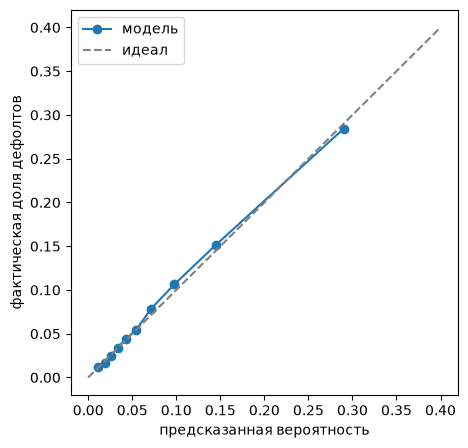

In [12]:
from sklearn.calibration import calibration_curve

frac_true, mean_pred = calibration_curve(y_va, p_va, n_bins=10, strategy="quantile")

plt.figure(figsize=(5, 5))
plt.plot(mean_pred, frac_true, marker="o", label="модель")
plt.plot([0, 0.4], [0, 0.4], "--", color="grey", label="идеал")
plt.xlabel("предсказанная вероятность")
plt.ylabel("фактическая доля дефолтов")
plt.legend()

print("средний прогноз:", round(p_va.mean(), 4), "| фактическая доля дефолтов:", round(y_va.mean(), 4))